In [ ]:
"""
Minor Project: CNN Image Classification (CIFAR-10) & Streamlit App
Student Name: Atharva Ingale
File: AtharvaIngale_CNN_Streamlit_Project.py
"""

# ==============================================================================
# PART A: CNN IMAGE CLASSIFICATION (CIFAR-10)
# ==============================================================================
def run_cnn():
    # Import Libraries
    import tensorflow as tf
    from tensorflow.keras import layers, models
    import matplotlib.pyplot as plt
    import numpy as np

In [ ]:
import tensorflow as tf

(X_train, y_train), (X_test, y_test) = tf.keras.datasets.cifar10.load_data()
y_train = y_train.flatten()
y_test = y_test.flatten()

class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1396s 8us/step
X_train shape: (50000, 32, 32, 3)
X_test shape: (10000, 32, 32, 3)


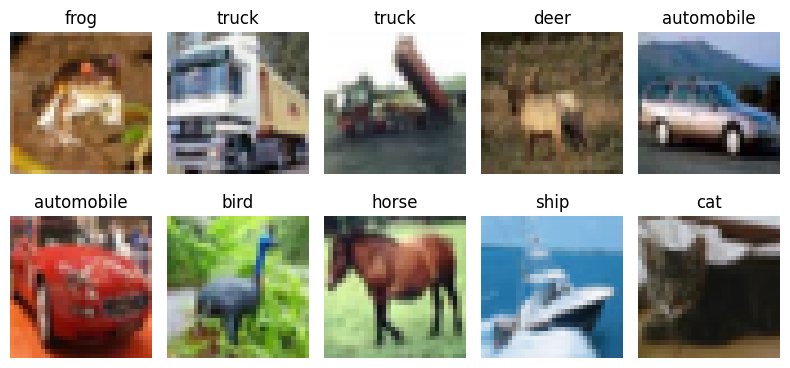

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
X_train = X_train / 255.0
X_test = X_test / 255.0


In [ ]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 167,562 (654.54 KB)

 Trainable params: 167,562 (654.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(X_train, y_train, epochs=5, validation_data=(X_test, y_test))

Epoch 1/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 71s 44ms/step - accuracy: 0.4795 - loss: 1.4517 - val_accuracy: 0.5743 - val_loss: 1.2055
Epoch 2/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 64s 41ms/step - accuracy: 0.6156 - loss: 1.0958 - val_accuracy: 0.6384 - val_loss: 1.0382
Epoch 3/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 81s 40ms/step - accuracy: 0.6612 - loss: 0.9697 - val_accuracy: 0.6317 - val_loss: 1.0388
Epoch 4/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 62s 39ms/step - accuracy: 0.6894 - loss: 0.8834 - val_accuracy: 0.6760 - val_loss: 0.9287
Epoch 5/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 81s 39ms/step - accuracy: 0.7141 - loss: 0.8199 - val_accuracy: 0.6892 - val_loss: 0.9046


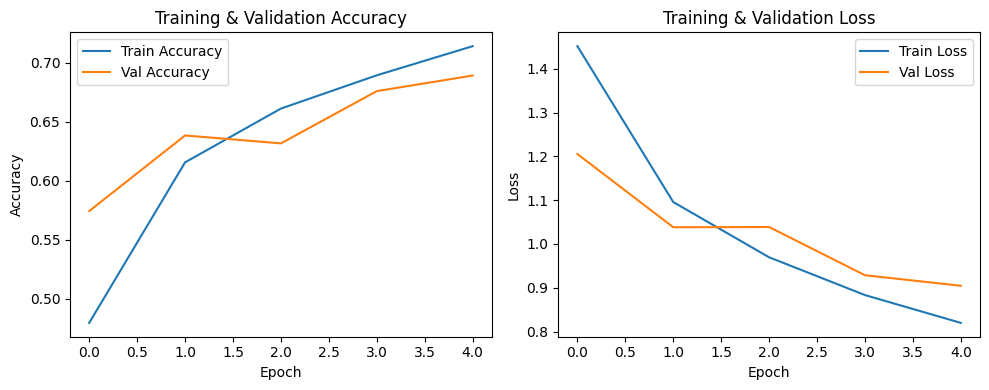

In [ ]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Training & Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Training & Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.6892 - loss: 0.9046
Test accuracy: 0.6892
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step


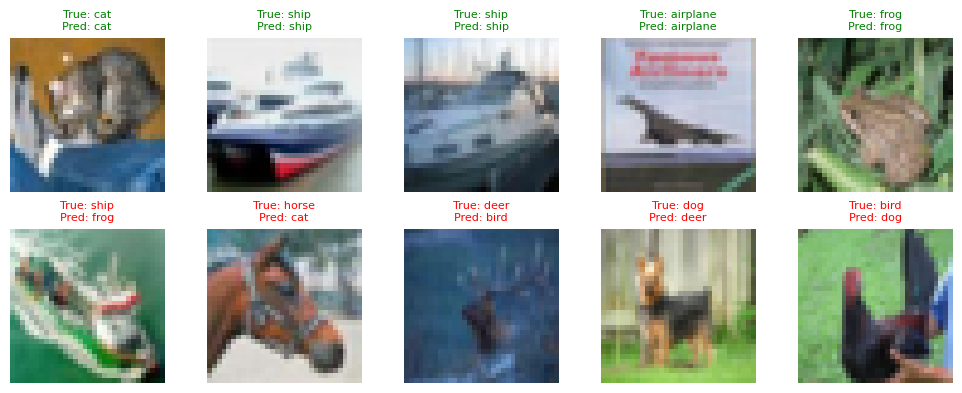

In [ ]:
import numpy as np

test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Test accuracy: {test_acc:.4f}")

predictions = model.predict(X_test)
pred_labels = np.argmax(predictions, axis=1)

correct = np.where(pred_labels == y_test)[0]
incorrect = np.where(pred_labels != y_test)[0]

plt.figure(figsize=(10, 4))
for i in range(5):
    idx_c = correct[i]
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[idx_c])
    plt.title(f"True: {class_names[y_test[idx_c]]}\nPred: {class_names[pred_labels[idx_c]]}", color='green', fontsize=8)
    plt.axis('off')

    idx_w = incorrect[i]
    plt.subplot(2, 5, i + 6)
    plt.imshow(X_test[idx_w])
    plt.title(f"True: {class_names[y_test[idx_w]]}\nPred: {class_names[pred_labels[idx_w]]}", color='red', fontsize=8)
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# PART B: STREAMLIT APPLICATION (STUDENT MARKS CALCULATOR)
# ==============================================================================
def run_streamlit():
    import streamlit as st

    st.title("Student Marks & Percentage Calculator")
    st.write("Enter your name and marks in 5 subjects (out of 100) to calculate your total, percentage, and grade.")

In [ ]:
!pip install -q streamlit

In [ ]:
import streamlit as st

# User Inputs
name = st.text_input("Enter Student Name")
m1 = st.number_input("Subject 1 Marks", min_value=0, max_value=100, value=75)
m2 = st.number_input("Subject 2 Marks", min_value=0, max_value=100, value=80)
m3 = st.number_input("Subject 3 Marks", min_value=0, max_value=100, value=70)
m4 = st.number_input("Subject 4 Marks", min_value=0, max_value=100, value=85)
m5 = st.number_input("Subject 5 Marks", min_value=0, max_value=100, value=90)

2026-11-20 16:00:30.796 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-20 16:00:30.797 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-20 16:00:30.799 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-20 16:00:30.800 WARNING streamlit.runtime.state.session_state_proxy: Session state does not function when running a script without `streamlit run`
2026-11-20 16:00:30.803 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-20 16:00:31.132 
  command:

    streamlit run /usr/local/lib/python3.13/

In [ ]:
# Processing & Output
if st.button("Calculate Result"):
    if name.strip() == "":
        st.warning("Please enter your name first.")
    else:
        total = m1 + m2 + m3 + m4 + m5
        percentage = (total / 500) * 100

        if percentage >= 75:
            grade = "Distinction"
        elif percentage >= 60:
            grade = "First Class"
        elif percentage >= 40:
            grade = "Pass"
        else:
            grade = "Fail"

        st.success(f"Result for {name}")
        st.write(f"**Total Marks:** {total} / 500")
        st.write(f"**Percentage:** {percentage:.2f}%")
        st.write(f"**Grade:** {grade}")

2026-11-20 16:01:50.693 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-20 16:01:50.695 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-20 16:01:50.696 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-20 16:01:50.697 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-20 16:01:50.698 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


In [ ]:

# RUN CONTROLLER
# ==============================================================================
if __name__ == "__main__":
    try:
        from streamlit.runtime.scriptrunner import get_script_run_ctx
        if get_script_run_ctx() is not None:
            run_streamlit()
        else:
            run_cnn()
    except ImportError:
        run_cnn()

2026-11-20 16:02:08.892 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
